# Учебное исследование территории: Березники (Пермский край)

Этот ноутбук показывает полный цикл работы с [BlocksNet](https://github.com/aimclub/blocksnet) на примере города Березники:

1. загрузка данных (из готовых GeoJSON или из OpenStreetMap);
2. нарезка городских кварталов;
3. назначение функциональных зон;
4. загрузка графов доступности (пешеходный и автомобильный) и расчёт времени в пути между кварталами;
5. агрегация зданий и школ по кварталам;
6. расчёт показателей: обеспеченность школами, плотность застройки, морфотипы, доступность территорий.

Версия BlocksNet: **1.0.0a9**.

## Как пользоваться этим ноутбуком

- Запускайте Jupyter из корня проекта (`E:\Projects\python-package-boilerplate`), чтобы пути к данным совпадали.
- В меню **Kernel → Change kernel** выберите ядро `.venv`.
- Ячейки выполняются сверху вниз: **Kernel → Run All** или по очереди (Shift+Enter).
- Данные хранятся в `examples/data/berezniki/`. Если файла нет — он скачивается из OpenStreetMap и сохраняется. Поэтому повторный запуск проходит быстрее.
- Результаты сохраняются в `examples/data/berezniki/processed/` (GeoJSON и CSV).
- **После подготовки кварталов есть остановка** — перед расчётами сообщите, какие метрики нужны.
- Население: модельная оценка BlocksNet по зданиям OSM, откалиброванная к численности Росстата (132 841 чел. на 01.01.2025); см. раздел 7. Вместимость школ — численность учеников с портала schoolotzyv.ru (`raw/schools_capacity.csv`), для школ без данных — 250 мест по умолчанию BlocksNet; см. раздел 8.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import osmnx as ox
import pandas as pd


def _find_data_dir():
    # Единый путь от корня проекта: examples/data/berezniki
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / 'examples' / 'data' / 'berezniki'
        if (candidate / 'raw').is_dir():
            return candidate
    return Path(r"E:\Projects\python-package-boilerplate\examples\data\berezniki")


DATA_DIR = _find_data_dir()
BASE_DIR = DATA_DIR.parent.parent
RAW_DIR = DATA_DIR / 'raw'
PROCESSED_DIR = DATA_DIR / 'processed'
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

TERRITORY = 'Березники, Пермский край, Россия'

plt.rcParams['figure.figsize'] = (10, 8)

print('Папка данных:', DATA_DIR)
print('Готовые файлы в raw:', sorted(p.name for p in RAW_DIR.glob('*.geojson')))
print('Готовые файлы в processed:', sorted(p.name for p in PROCESSED_DIR.glob('*')))

Папка данных: e:\Projects\python-package-boilerplate\examples\data\berezniki
Готовые файлы в raw: ['boundaries.geojson', 'buildings.geojson', 'functional_zones.geojson', 'railways.geojson', 'roads.geojson', 'schools.geojson', 'water.geojson']
Готовые файлы в processed: ['accessibility_matrix_drive.csv', 'accessibility_matrix_walk.csv', 'area_accessibility_drive.geojson', 'area_accessibility_walk.geojson', 'blocks.geojson', 'blocks_land_use.geojson', 'buildings_blocks.geojson', 'density_indicators.geojson', 'graph_drive.graphml', 'graph_walk.graphml', 'provision_drive.geojson', 'provision_links_drive.csv', 'provision_links_walk.csv', 'provision_walk.geojson', 'schools_blocks.geojson', 'spacematrix_morphotypes.geojson', 'strelka_morphotypes.geojson']


### Сравнение папок данных

Проверяем содержимое `data/berezniki` и `examples/data/berezniki`. Уникальные файлы сохраняются, ничего не удаляется.

In [2]:
import os

old_data_dir = Path(r"E:\Projects\python-package-boilerplate\data\berezniki")
new_data_dir = Path(r"E:\Projects\python-package-boilerplate\examples\data\berezniki")

print('Старая папка (data/berezniki):', old_data_dir)
print('  Существует:', old_data_dir.exists())
if old_data_dir.exists():
    old_files = set()
    for root, dirs, files in os.walk(old_data_dir):
        for f in files:
            rel = Path(root).relative_to(old_data_dir)
            old_files.add(str(rel / f))
    print('  Файлов:', len(old_files))
    for f in sorted(old_files):
        print('   -', f)

print()
print('Новая папка (examples/data/berezniki):', new_data_dir)
print('  Существует:', new_data_dir.exists())
if new_data_dir.exists():
    new_files = set()
    for root, dirs, files in os.walk(new_data_dir):
        for f in files:
            rel = Path(root).relative_to(new_data_dir)
            new_files.add(str(rel / f))
    print('  Файлов:', len(new_files))
    for f in sorted(new_files):
        print('   -', f)

print()
only_in_old = old_files - new_files if old_data_dir.exists() else set()
only_in_new = new_files - old_files if new_data_dir.exists() else set()
print('Только в старой папке (будут скопированы):', len(only_in_old))
for f in sorted(only_in_old):
    print('  -', f)
print('Только в новой папке:', len(only_in_new))
for f in sorted(only_in_new):
    print('  -', f)

if only_in_old:
    print()
    print('Копируем уникальные файлы из старой папки в новую...')
    for rel_path in only_in_old:
        src = old_data_dir / rel_path
        dst = new_data_dir / rel_path
        dst.parent.mkdir(parents=True, exist_ok=True)
        import shutil
        shutil.copy2(src, dst)
        print('  Скопировано:', rel_path)
    print('Готово. Старая папка не удалена.')

Старая папка (data/berezniki): E:\Projects\python-package-boilerplate\data\berezniki
  Существует: True
  Файлов: 81
   - processed\blocks.geojson
   - processed\blocks_land_use.geojson
   - raw\boundaries.geojson
   - raw\buildings.geojson
   - raw\functional_zones.geojson
   - raw\osm_center.xml
   - raw\osm_combined.xml
   - raw\osm_tiles\tile_0_0.xml
   - raw\osm_tiles\tile_0_1.xml
   - raw\osm_tiles\tile_0_2.xml
   - raw\osm_tiles\tile_0_3.xml
   - raw\osm_tiles\tile_0_4.xml
   - raw\osm_tiles\tile_0_5.xml
   - raw\osm_tiles\tile_0_6.xml
   - raw\osm_tiles\tile_1_0.xml
   - raw\osm_tiles\tile_1_1.xml
   - raw\osm_tiles\tile_1_2.xml
   - raw\osm_tiles\tile_1_3.xml
   - raw\osm_tiles\tile_1_4.xml
   - raw\osm_tiles\tile_1_5.xml
   - raw\osm_tiles\tile_1_6.xml
   - raw\osm_tiles\tile_2_0.xml
   - raw\osm_tiles\tile_2_1.xml
   - raw\osm_tiles\tile_2_2.xml
   - raw\osm_tiles\tile_2_3.xml
   - raw\osm_tiles\tile_2_4.xml
   - raw\osm_tiles\tile_2_5.xml
   - raw\osm_tiles\tile_2_6.xml
   

## 1. Загрузка данных

Приоритет — готовые файлы в `data/berezniki/raw/`. Если файла нет, он скачивается из OpenStreetMap через `osmnx` с теми же тегами, что в примере `pipeline.ipynb`.

Читаю готовый файл границ: e:\Projects\python-package-boilerplate\examples\data\berezniki\raw\boundaries.geojson
Территория: Березники, Пермский край, Россия
CRS: EPSG:32640
Площадь границы, км²: 428.66


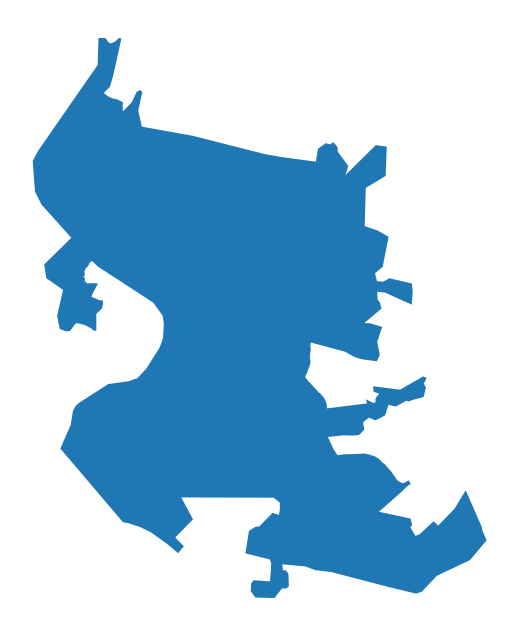

In [3]:
boundaries_path = RAW_DIR / 'boundaries.geojson'
if boundaries_path.exists():
    print('Читаю готовый файл границ:', boundaries_path)
    boundaries = gpd.read_file(boundaries_path)
else:
    print('Скачиваю границы территории из OpenStreetMap...')
    boundaries = ox.geocode_to_gdf(TERRITORY)
    boundaries.to_file(boundaries_path, driver='GeoJSON')
    print('Сохранено:', boundaries_path)

crs = boundaries.estimate_utm_crs()
boundaries = boundaries.to_crs(crs)
print('Территория:', TERRITORY)
print('CRS:', crs)
print('Площадь границы, км²:', round(boundaries.area.sum() / 1e6, 2))
boundaries.plot().set_axis_off()

In [4]:
bc_tags = {
    'roads': {
        'highway': ['construction', 'crossing', 'living_street', 'motorway', 'motorway_link',
                    'motorway_junction', 'pedestrian', 'primary', 'primary_link', 'raceway',
                    'residential', 'road', 'secondary', 'secondary_link', 'services', 'tertiary',
                    'tertiary_link', 'track', 'trunk', 'trunk_link', 'turning_circle',
                    'turning_loop', 'unclassified'],
        'service': ['living_street', 'emergency_access'],
    },
    'railways': {'railway': 'rail'},
    'water': {
        'riverbank': True, 'reservoir': True, 'basin': True, 'dock': True, 'canal': True,
        'pond': True, 'natural': ['water', 'bay'], 'waterway': ['river', 'canal', 'ditch'],
        'landuse': 'basin', 'water': 'lake',
    },
}


def load_or_download(name, tags):
    path = RAW_DIR / f'{name}.geojson'
    if path.exists():
        print('Читаю готовый файл:', path.name)
        gdf = gpd.read_file(path)
    else:
        print('Файл не найден. Скачиваю из OpenStreetMap, это может занять несколько минут:', name)
        polygon = boundaries.to_crs(4326).union_all()
        gdf = ox.features_from_polygon(polygon, tags=tags).reset_index(drop=True)
        gdf.to_file(path, driver='GeoJSON')
        print('Сохранено:', path.name)
    return gdf.to_crs(crs)

In [5]:
roads = load_or_download('roads', bc_tags['roads'])
railways = load_or_download('railways', bc_tags['railways'])
water = load_or_download('water', bc_tags['water'])
print('Дорог:', len(roads), '| ж/д:', len(railways), '| воды:', len(water))

Читаю готовый файл: roads.geojson
Читаю готовый файл: railways.geojson
Читаю готовый файл: water.geojson
Дорог: 1707 | ж/д: 487 | воды: 307


In [6]:
functional_zones = load_or_download('functional_zones', {'landuse': True})
buildings = load_or_download('buildings', {'building': True})
schools = load_or_download('schools', {'amenity': 'school'})
print('Функциональных зон:', len(functional_zones), '| зданий:', len(buildings), '| школ:', len(schools))

Читаю готовый файл: functional_zones.geojson


Читаю готовый файл: buildings.geojson
Читаю готовый файл: schools.geojson
Функциональных зон: 803 | зданий: 10883 | школ: 21


## 2. Подготовка геометрии

Оставляем только нужные типы геометрий и переводим все слои в единую проекцию (UTM, EPSG:32640 для Березников), чтобы измерения шли в метрах.

In [7]:
water = water[water.geom_type.isin(['Polygon', 'MultiPolygon', 'LineString', 'MultiLineString'])].copy()
roads = roads[roads.geom_type.isin(['LineString', 'MultiLineString'])].copy()
railways = railways[railways.geom_type.isin(['LineString', 'MultiLineString'])].copy()
for gdf in [water, roads, railways, boundaries]:
    gdf.to_crs(crs, inplace=True)
print('Геометрия подготовлена. CRS:', crs)

Геометрия подготовлена. CRS: EPSG:32640


## 3. Нарезка кварталов

`preprocess_urban_objects` раскладывает объекты на линии (дороги, ж/д) и полигоны (вода). `cut_urban_blocks` режет территорию на кварталы по этим линиям и вырезает воду.

In [8]:
from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks

lines, polygons = preprocess_urban_objects(roads, railways, water)
blocks = cut_urban_blocks(boundaries, lines, polygons)
print('Кварталов получено:', len(blocks))

e:\Projects\python-package-boilerplate\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
2026-10-22 21:47:39.123 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:44 - Checking roads schema
2026-10-22 21:47:39.135 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:51 - Checking railways schema
2026-10-22 21:47:39.142 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:58 - Checking water schema
2026-10-22 21:47:39.153 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:51 - Checking boundaries schema
2026-10-22 21:47:39.161 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:55 - Checking line objects schema
2026-10-22 21:47:39.176 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess

Кварталов получено: 932


Сохранено: e:\Projects\python-package-boilerplate\examples\data\berezniki\processed\blocks.geojson


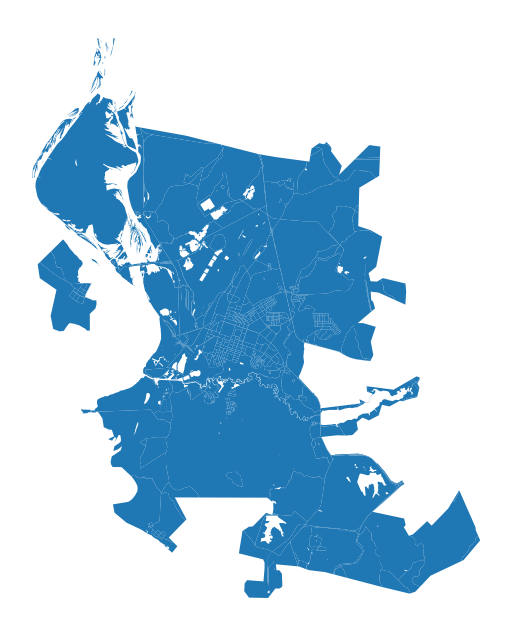

In [9]:
blocks_path = PROCESSED_DIR / 'blocks.geojson'
blocks.to_file(blocks_path, driver='GeoJSON')
print('Сохранено:', blocks_path)
blocks.plot().set_axis_off()

> ### СТОП: ОСТАНОВКА ПОСЛЕ ПОДГОТОВКИ КВАРТАЛОВ
>
> Кварталы готовы и сохранены в `data/berezniki/processed/blocks.geojson`.
>
> **Перед запуском расчётов сообщите, какие метрики нужны.** Ниже идут ячейки: функциональные зоны, графы и матрицы времени, здания, школы и все показатели. Можно запускать их все подряд или только нужные.

## 4. Функциональные зоны (land use)

`assign_land_use` сопоставляет кварталам функциональные зоны по правилам `rules` (тег `landuse` из OSM → категория `LandUse`).

In [10]:
from blocksnet.enums import LandUse
from blocksnet.blocks.assignment import assign_land_use

rules = {
    'commercial': LandUse.BUSINESS,
    'industrial': LandUse.INDUSTRIAL,
    'cemetery': LandUse.SPECIAL,
    'garages': LandUse.INDUSTRIAL,
    'residential': LandUse.RESIDENTIAL,
    'retail': LandUse.BUSINESS,
    'grass': LandUse.RECREATION,
    'farmland': LandUse.AGRICULTURE,
    'construction': LandUse.SPECIAL,
    'brownfield': LandUse.INDUSTRIAL,
    'forest': LandUse.RECREATION,
    'recreation_ground': LandUse.RECREATION,
    'religious': LandUse.SPECIAL,
    'flowerbed': LandUse.RECREATION,
    'military': LandUse.SPECIAL,
    'landfill': LandUse.TRANSPORT,
}

functional_zones = functional_zones.reset_index(drop=True).rename(columns={'landuse': 'functional_zone'})
blocks = assign_land_use(blocks, functional_zones, rules)
blocks['land_use'] = blocks['land_use'].apply(lambda lu: lu.value if isinstance(lu, LandUse) else lu)
print('Функциональные зоны назначены.')

2026-10-22 21:47:40.121 | WARNING  | blocksnet.blocks.assignment.land_use:_preprocess_functional_zones:17 - Functional zones not in rules: harbour, allotments, outdoors, railway, farmyard, meadow, reservoir, quarry


Функциональные зоны назначены.


Сохранено: e:\Projects\python-package-boilerplate\examples\data\berezniki\processed\blocks_land_use.geojson


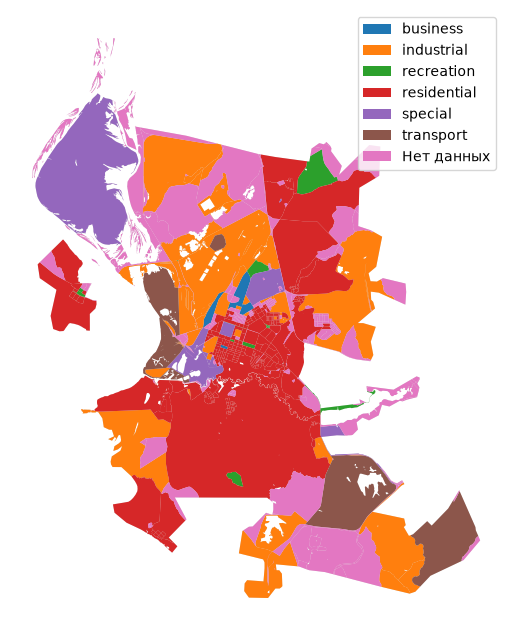

In [11]:
blocks_lu_path = PROCESSED_DIR / 'blocks_land_use.geojson'
blocks.to_file(blocks_lu_path, driver='GeoJSON')
print('Сохранено:', blocks_lu_path)
ax = blocks.plot(color='#ddd')
blocks_map = blocks.copy()
blocks_map["land_use_label"] = blocks_map["land_use"].map(
    lambda x: str(getattr(x, "value", x)) if x is not None else "Нет данных"
)
blocks_map.plot(
    column="land_use_label",
    categorical=True,
    legend=True,
    ax=ax
).set_axis_off()

## 5. Графы доступности: пешеходный и автомобильный

Источник графов — **OpenStreetMap**, через библиотеку `iduedu` (обёртка над `osmnx`), функция `blocksnet.relations.get_accessibility_graph`.

- **walk** — пешеходная сеть, скорость 5 км/ч;
- **drive** — автомобильная сеть, скорость по типу дороги.

Интермодальный граф (пешкий + общественный транспорт) **не строим**. Вес каждого ребра — `time_min`, время в пути в **минутах**. Готовые графы сохраняются в `processed/graph_walk.graphml` и `processed/graph_drive.graphml`.

In [12]:
from blocksnet.relations import get_accessibility_graph


def build_graph(graph_type, path):
    print(f"Скачиваю граф '{graph_type}' из OpenStreetMap (iduedu/osmnx), это может занять время...")
    graph = get_accessibility_graph(boundaries, graph_type)
    ox.save_graphml(graph, path)
    print('Сохранено:', path.name)
    return graph


def normalize_graph(graph):
    # GraphML может сохранить числа как строки — приводим к float
    for _, data in graph.nodes(data=True):
        data['x'] = float(data['x'])
        data['y'] = float(data['y'])
    for _, _, data in graph.edges(data=True):
        data['time_min'] = float(data['time_min'])
    # Убираем «ловушки» и приводим id узлов к 0..n-1, иначе матрица времени будет неверной
    from iduedu.utils.utils import remove_weakly_connected_nodes
    if graph.is_directed():
        graph = remove_weakly_connected_nodes(graph)
    graph = nx.convert_node_labels_to_integers(graph)
    return graph


def graph_has_time(graph):
    return isinstance(graph, nx.Graph) and all('time_min' in d for _, _, d in graph.edges(data=True)) and all('x' in d and 'y' in d for _, d in graph.nodes(data=True))


def load_or_build_graph(graph_type):
    path = PROCESSED_DIR / f'graph_{graph_type}.graphml'
    existing = globals().get(f'graph_{graph_type}')
    if graph_has_time(existing):
        print('Использую граф из памяти:', graph_type)
        existing = normalize_graph(existing)
        existing.graph['crs'] = int(existing.graph.get('crs', crs.to_epsg()))
        print('  узлов:', existing.number_of_nodes(), '| рёбер:', existing.number_of_edges(), '| crs:', existing.graph['crs'])
        return existing
    graph = None
    if path.exists():
        try:
            print('Читаю готовый граф:', path.name)
            graph = ox.load_graphml(path, edge_dtypes={'time_min': float}, graph_dtypes={'crs': int})
        except Exception as exc:
            print('Не удалось прочитать граф, скачиваю заново. Причина:', exc)
            graph = None
    if graph is None or not all('time_min' in d for _, _, d in graph.edges(data=True)):
        graph = build_graph(graph_type, path)
    graph = normalize_graph(graph)
    graph.graph['crs'] = int(graph.graph.get('crs', crs.to_epsg()))
    print('  узлов:', graph.number_of_nodes(), '| рёбер:', graph.number_of_edges(), '| crs:', graph.graph['crs'])
    return graph


graph_walk = load_or_build_graph('walk')
graph_drive = load_or_build_graph('drive')

Читаю готовый граф: graph_walk.graphml
  узлов: 13003 | рёбер: 35890 | crs: 32640
Читаю готовый граф: graph_drive.graphml
  узлов: 1767 | рёбер: 4686 | crs: 32640


In [13]:
for gname, g in [('walk', graph_walk), ('drive', graph_drive)]:
    sample = list(g.edges(data=True))[:3]
    print(f'Граф {gname}: примеры рёбер (u, v, time_min)')
    for u, v, d in sample:
        print(' ', u, '->', v, '| time_min =', round(d.get('time_min', float('nan')), 3))

Граф walk: примеры рёбер (u, v, time_min)
  0 -> 1 | time_min = 1.201
  0 -> 2 | time_min = 0.92
  0 -> 3 | time_min = 1.197
Граф drive: примеры рёбер (u, v, time_min)
  0 -> 1 | time_min = 0.051
  0 -> 2 | time_min = 0.066
  1 -> 0 | time_min = 0.051


## 6. Матрицы времени между кварталами

`calculate_accessibility_matrix` считает матрицу `n × n` (время в минутах) между всеми парами кварталов. Считаем для обоих графов и сравниваем.

In [14]:
from blocksnet.relations import calculate_accessibility_matrix

print('Считаю матрицу времени для пешеходного графа...')
acc_mx_walk = calculate_accessibility_matrix(blocks, graph_walk)
print('Считаю матрицу времени для автомобильного графа...')
acc_mx_drive = calculate_accessibility_matrix(blocks, graph_drive)
print('Размер матриц:', acc_mx_walk.shape, '(значения в минутах)')

Считаю матрицу времени для пешеходного графа...
Считаю матрицу времени для автомобильного графа...
Размер матриц: (932, 932) (значения в минутах)


In [15]:
acc_mx_walk.to_csv(PROCESSED_DIR / 'accessibility_matrix_walk.csv')
acc_mx_drive.to_csv(PROCESSED_DIR / 'accessibility_matrix_drive.csv')
print('Матрицы сохранены в CSV (время в пути, минуты).')

Матрицы сохранены в CSV (время в пути, минуты).


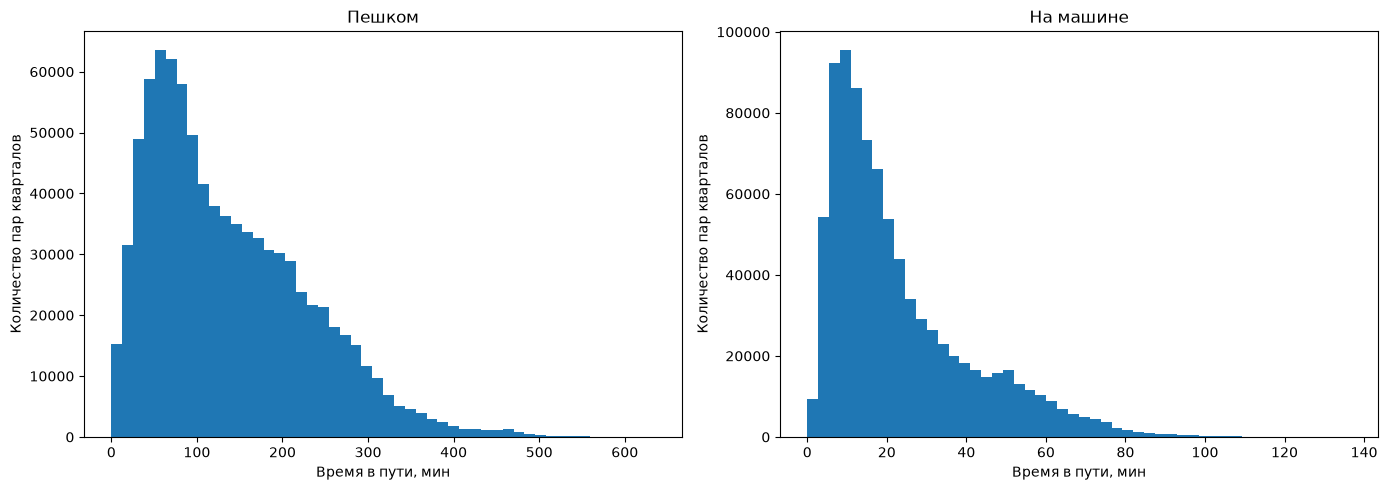

Пешком: медиана = 115.94 мин
На машине: медиана = 17.25 мин


In [16]:
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, mx, title in zip(axes, [acc_mx_walk, acc_mx_drive], ['Пешком', 'На машине']):
    vals = mx.values[np.isfinite(mx.values)]
    ax.hist(vals, bins=50)
    ax.set_title(title)
    ax.set_xlabel('Время в пути, мин')
    ax.set_ylabel('Количество пар кварталов')
plt.tight_layout()
plt.show()

print('Пешком: медиана =', round(float(np.nanmedian(acc_mx_walk.values)), 2), 'мин')
print('На машине: медиана =', round(float(np.nanmedian(acc_mx_drive.values)), 2), 'мин')

## 7. Здания и население

### Почему население получалось ≈ 44 тыс. вместо ≈ 133 тыс.

Функция `impute_buildings` считает жителей только в зданиях с `is_living = True`:
`население = этажность × площадь контура × 0,9 / 30 м² на человека`.
В OSM для Березников это работает плохо по двум причинам:

1. **Многоквартирные дома почти не размечены как жилые.** Тег `apartments` стоит лишь у 133 зданий, а около тысячи крупных пятиэтажек и девятиэтажек отмечены просто `building=yes`. Модель считала их нежилыми.
2. **У большинства жилых домов нет этажности.** Если тега `building:levels` нет, BlocksNet подставляет 1 этаж, и пятиэтажка превращается в одноэтажный дом.

### Что меняем (допущения, их видно в колонках `living_source` и `floors_source`)

- `building=yes` считаем жилым, если здание стоит **внутри жилой зоны OSM** (`landuse=residential`), у него нет тегов магазина, учреждения или офиса и площадь контура не меньше 40 м² (меньше — гаражи и сараи).
- Если этажность неизвестна, у **крупного жилого здания** (контур ≥ 300 м², не частный дом) ставим **5 этажей**. Это медиана этажности жилых зданий Березников, у которых она указана в OSM. Остальным — 1 этаж, как в BlocksNet.
- **Калибровка.** Модель всё равно даёт лишь распределение жителей между домами, а не точную сумму (часть домов в зоне провалов расселена, но осталась в OSM). Поэтому общую сумму приводим к официальной численности города, **132 841 чел. на 01.01.2025 (Росстат)**, сохраняя пропорции между домами. Исходная модельная оценка сохраняется в колонке `population_model`.


In [17]:
from blocksnet.preprocessing.imputing import impute_buildings
from blocksnet.blocks.aggregation import aggregate_objects

# --- Параметры оценки населения (допущения, можно менять) ---
OFFICIAL_POPULATION = 132_841      # Росстат, численность г. Березники на 01.01.2025
LIVING_DEMAND = 30                 # м² общей площади на 1 жителя
MIN_HOUSE_FOOTPRINT = 40           # м²: меньше — гаражи, сараи, бани
APARTMENT_MIN_FOOTPRINT = 300      # м²: крупный контур — многоквартирный дом
APARTMENT_DEFAULT_FLOORS = 5       # медиана указанной этажности крупных жилых домов
is_living_tags = ['residential', 'house', 'apartments', 'detached', 'terrace', 'dormitory']
private_house_tags = ['house', 'detached', 'terrace']
non_residential_keys = ['amenity', 'shop', 'office', 'craft', 'healthcare', 'tourism', 'leisure']

buildings_raw = gpd.read_file(RAW_DIR / 'buildings.geojson').to_crs(crs)
building_points = buildings_raw[buildings_raw.geom_type == 'Point'].copy()
buildings = buildings_raw[buildings_raw.geom_type.isin(['Polygon', 'MultiPolygon'])].copy().reset_index(drop=True)
print('Контуров зданий для расчёта:', len(buildings), '| точек без контура (не учитываем):', len(building_points))

tag = buildings['building'].astype('string').str.strip().str.lower()
levels = pd.to_numeric(buildings['building:levels'], errors='coerce')
footprint = buildings.area

# 1. Какие здания жилые
zones_raw = gpd.read_file(RAW_DIR / 'functional_zones.geojson').to_crs(crs)
residential_zones = zones_raw.loc[zones_raw['landuse'] == 'residential', ['geometry']]
points = gpd.GeoDataFrame(geometry=buildings.representative_point(), crs=crs)
in_residential_zone = points.index.isin(gpd.sjoin(points, residential_zones, predicate='within').index)

present_keys = [k for k in non_residential_keys if k in buildings.columns]
has_non_residential_tag = buildings[present_keys].notna().any(axis=1) if present_keys else pd.Series(False, index=buildings.index)

living_by_tag = tag.isin(is_living_tags).fillna(False).to_numpy(dtype=bool)
living_by_zone = (tag.eq('yes').fillna(False).to_numpy(dtype=bool) & in_residential_zone
                  & ~has_non_residential_tag.to_numpy(dtype=bool) & (footprint >= MIN_HOUSE_FOOTPRINT).to_numpy())
buildings['is_living'] = living_by_tag | living_by_zone
living_source = np.select([living_by_tag, living_by_zone], ['тег OSM', 'building=yes в жилой зоне'], default='нежилое')

# 2. Этажность
apartment_like = (buildings['is_living'].to_numpy(dtype=bool) & (footprint >= APARTMENT_MIN_FOOTPRINT).to_numpy()
                  & ~tag.isin(private_house_tags).fillna(False).to_numpy(dtype=bool))
known_floors = (levels.notna() & (levels > 0)).to_numpy(dtype=bool)
floors = levels.where(known_floors)
floors = floors.mask(~known_floors & apartment_like, APARTMENT_DEFAULT_FLOORS)
floors = floors.mask(~known_floors & ~apartment_like, 1)
buildings['number_of_floors'] = floors
floors_source = np.select([known_floors, apartment_like], ['тег OSM', f'допущение: {APARTMENT_DEFAULT_FLOORS} эт.'], default='допущение: 1 эт.')

building_meta = pd.DataFrame({
    'building_tag': tag.fillna('нет'),
    'living_source': living_source,
    'floors_source': floors_source,
}, index=buildings.index)

# 3. Площади и модельное население (BlocksNet)
buildings = impute_buildings(buildings[['geometry', 'is_living', 'number_of_floors']], default_living_demand=LIVING_DEMAND)
buildings = buildings.join(building_meta)
buildings['population'] = buildings['population'].fillna(0)
buildings['population_model'] = buildings['population']

# 4. Калибровка к официальной численности
model_total = buildings['population_model'].sum()
calibration_k = OFFICIAL_POPULATION / model_total
buildings['population'] = buildings['population_model'] * calibration_k

print()
print('Жилых зданий:', int(buildings['is_living'].sum()))
print(buildings.loc[buildings['is_living'], 'living_source'].value_counts().to_string())
print()
print('Источник этажности жилых зданий:')
print(buildings.loc[buildings['is_living'], 'floors_source'].value_counts().to_string())
print()
print(f'Модельная оценка населения (до калибровки): {model_total:,.0f} чел.')
print(f'Официальная численность (Росстат, 01.01.2025): {OFFICIAL_POPULATION:,} чел.')
print(f'Коэффициент калибровки: {calibration_k:.3f}')

# 5. Агрегация по кварталам (только числовые поля BlocksNet)
agg_cols = ['geometry', 'is_living', 'number_of_floors', 'footprint_area', 'build_floor_area',
            'living_area', 'non_living_area', 'population', 'population_model']
buildings_blocks, buildings_outside = aggregate_objects(blocks, buildings[agg_cols])
print()
print(f'Население по кварталам: {buildings_blocks["population"].sum():,.0f} чел.')
print('Зданий вне кварталов (попали на дороги или воду):', len(buildings_outside),
      '| их жителей:', round(float(buildings_outside['population'].sum())))


Контуров зданий для расчёта: 10869 | точек без контура (не учитываем): 14


2026-10-22 21:47:56.121 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column footprint_area not found and will be initialized as None
2026-10-22 21:47:56.122 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column build_floor_area not found and will be initialized as None
2026-10-22 21:47:56.122 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column living_area not found and will be initialized as None
2026-10-22 21:47:56.123 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column non_living_area not found and will be initialized as None
2026-10-22 21:47:56.123 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column population not found and will be initialized as None
2026-10-22 21:47:56.197 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-10-22 21:47:56.


Жилых зданий: 6509
living_source
тег OSM                      4155
building=yes в жилой зоне    2354

Источник этажности жилых зданий:
floors_source
допущение: 1 эт.    3531
тег OSM             2869
допущение: 5 эт.     109

Модельная оценка населения (до калибровки): 174,002 чел.
Официальная численность (Росстат, 01.01.2025): 132,841 чел.
Коэффициент калибровки: 0.763

Население по кварталам: 132,841 чел.
Зданий вне кварталов (попали на дороги или воду): 2 | их жителей: 0


### Диагностика оценки населения

Проверяем, как распределились жители: по типу определения жилья, по этажности и по кварталам. Если какой-то квартал выглядит странно, его можно найти на карте ниже.


In [18]:
total_buildings = len(buildings)
living = buildings[buildings['is_living']]
print(f'Всего зданий: {total_buildings}')
print(f'Жилых: {len(living)} ({len(living) / total_buildings * 100:.1f}%)')
print()
print('Жители по способу определения жилья (после калибровки):')
display(living.groupby('living_source')['population'].agg(['count', 'sum']).round(0)
        .rename(columns={'count': 'Зданий', 'sum': 'Жителей'}))
print('Жители по источнику этажности:')
display(living.groupby('floors_source')['population'].agg(['count', 'sum']).round(0)
        .rename(columns={'count': 'Зданий', 'sum': 'Жителей'}))
print('Теги building (топ-15) у всех зданий:')
display(buildings['building_tag'].value_counts().head(15).to_frame('Зданий'))
print('Кварталы с наибольшим населением:')
display(buildings_blocks[['population', 'population_model', 'count']].sort_values('population', ascending=False).head(10).round(0))


Всего зданий: 10869
Жилых: 6509 (59.9%)

Жители по способу определения жилья (после калибровки):


,Зданий,Жителей
living_source,,
building=yes в жилой зоне,2354,98240.0
тег OSM,4155,34601.0


Жители по источнику этажности:


,Зданий,Жителей
floors_source,,
допущение: 1 эт.,3531,8743.0
допущение: 5 эт.,109,9384.0
тег OSM,2869,114714.0


Теги building (топ-15) у всех зданий:


,Зданий
building_tag,
yes,4988
detached,2136
house,1725
industrial,565
garages,472
service,291
residential,159
apartments,133
hut,86


Кварталы с наибольшим населением:


,population,population_model,count
11,12320.0,16138.0,166.0
152,8538.0,11183.0,104.0
17,5317.0,6965.0,106.0
675,5046.0,6610.0,14.0
291,3848.0,5040.0,38.0
293,3811.0,4992.0,54.0
113,3668.0,4804.0,37.0
3,3467.0,4541.0,39.0
181,3152.0,4128.0,54.0
234,2933.0,3842.0,45.0


Сохранено: e:\Projects\python-package-boilerplate\examples\data\berezniki\processed\buildings_blocks.geojson


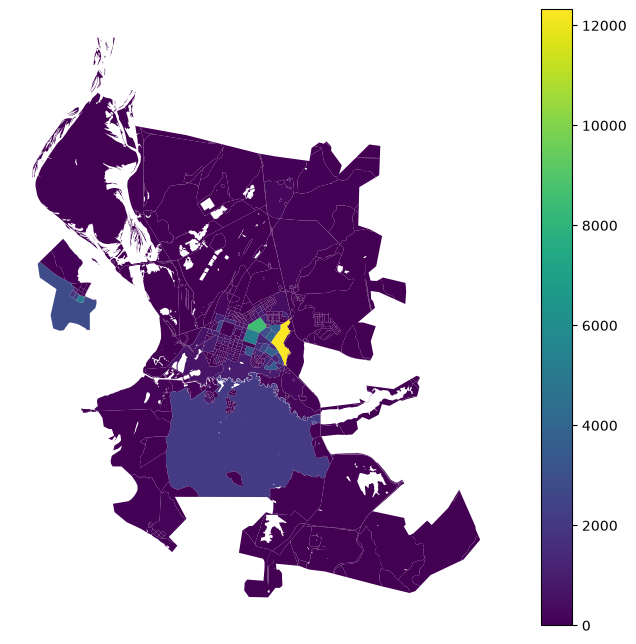

In [19]:
buildings_blocks_path = PROCESSED_DIR / 'buildings_blocks.geojson'
buildings_blocks.to_file(buildings_blocks_path, driver='GeoJSON')
print('Сохранено:', buildings_blocks_path)
buildings_blocks.plot('population', legend=True).set_axis_off()

## 8. Сервисы (школы)

### Откуда берём вместимость

В OSM вместимость (`capacity`) не указана ни у одной школы Березников. По умолчанию BlocksNet ставит каждой школе 250 мест: это даёт 5 250 мест на ~16 тыс. детей и делает обеспеченность заведомо заниженной.

Поэтому вместимость берём из таблицы `raw/schools_capacity.csv`. Это **фактическая численность учеников** каждой школы с портала schoolotzyv.ru (год на портале не указан). Это число учеников, а не проектная мощность зданий: если школа переполнена или учит в две смены, реальных мест может быть меньше.

- Если у школы в OSM несколько зданий (корпуса школ № 7 и № 30, дубли № 3 и № 22), численность делится между ними поровну.
- Если данных нет (вечерняя школа), остаётся 250 мест по умолчанию BlocksNet.

Источник каждой цифры — в колонке `capacity_source`.


In [20]:
import re
from blocksnet.preprocessing.imputing import impute_services

capacity_table = pd.read_csv(RAW_DIR / 'schools_capacity.csv')


def school_key(name):
    # 'Школа № 7. Корпус № 2' -> 'школа 7', 'Лицей № 1' -> 'лицей 1'
    if not isinstance(name, str):
        return None
    match = re.search(r'№\s*(\d+)', name)
    if not match:
        return None
    lower = name.lower()
    kind = 'лицей' if 'лицей' in lower else ('гимназия' if 'гимназ' in lower else 'школа')
    return f'{kind} {match.group(1)}'


schools = schools.reset_index(drop=True).copy()
schools['school_key'] = schools['name'].apply(school_key)
students = capacity_table.set_index('key')['students']
objects_per_school = schools.groupby('school_key')['school_key'].transform('count')
schools['capacity'] = schools['school_key'].map(students) / objects_per_school
schools['capacity_source'] = np.where(
    schools['capacity'].notna(),
    'численность учеников (schoolotzyv.ru)',
    'по умолчанию BlocksNet: 250 мест',
)
school_meta = schools[['name', 'school_key', 'capacity_source']].copy()

schools = impute_services(schools, 'school').join(school_meta)

unmatched = set(capacity_table['key']) - set(schools['school_key'].dropna())
if unmatched:
    print('В таблице есть школы, не найденные в OSM:', sorted(unmatched))

display(schools[['name', 'capacity', 'capacity_source']].sort_values('name').round(0))
print(schools.groupby('capacity_source')['capacity'].agg(['count', 'sum']).round(0).to_string())
print()
print('Суммарная вместимость школ:', int(round(schools['capacity'].sum())), 'мест')

schools_blocks = aggregate_objects(blocks, schools[['geometry', 'capacity']])[0]


,name,capacity,capacity_source
0,Вечерняя школа,250.0,по умолчанию BlocksNet: 250 мест
7,Гимназия № 9,946.0,численность учеников (schoolotzyv.ru)
11,Лицей № 1,523.0,численность учеников (schoolotzyv.ru)
6,Школа № 1,812.0,численность учеников (schoolotzyv.ru)
17,Школа № 11,1231.0,численность учеников (schoolotzyv.ru)
4,Школа № 12,667.0,численность учеников (schoolotzyv.ru)
19,Школа № 14,675.0,численность учеников (schoolotzyv.ru)
18,Школа № 16,972.0,численность учеников (schoolotzyv.ru)
12,Школа № 17,778.0,численность учеников (schoolotzyv.ru)
16,Школа № 2 имени М. Горького,1390.0,численность учеников (schoolotzyv.ru)


2026-10-22 21:47:57.127 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-10-22 21:47:57.128 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


                                       count      sum
capacity_source                                      
по умолчанию BlocksNet: 250 мест           1    250.0
численность учеников (schoolotzyv.ru)     20  16798.0

Суммарная вместимость школ: 17048 мест


Сохранено: e:\Projects\python-package-boilerplate\examples\data\berezniki\processed\schools_blocks.geojson

Колонки schools_blocks:
['geometry', 'capacity', 'count']



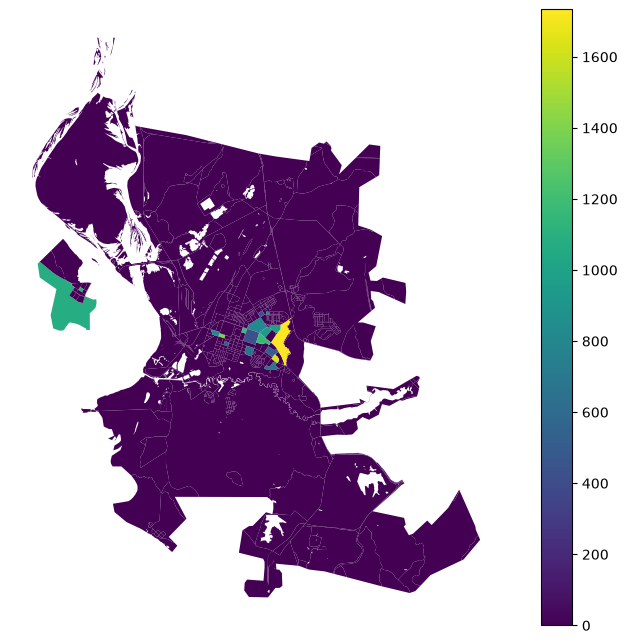

In [21]:
schools_blocks_path = PROCESSED_DIR / 'schools_blocks.geojson'
schools_blocks.to_file(schools_blocks_path, driver='GeoJSON')
print('Сохранено:', schools_blocks_path)
print()
print('Колонки schools_blocks:')
print(list(schools_blocks.columns))
print()
if 'capacity_source' in schools_blocks.columns:
    print('Распределение источников вместимости по кварталам:')
    print(schools_blocks['capacity_source'].value_counts().to_string())
schools_blocks.plot('capacity', legend=True).set_axis_off()

## 9. Показатели (все из `pipeline.ipynb`)

- `competitive_provision` — обеспеченность школами (сильная и слабая), с учётом времени в пути;
- `calculate_density_indicators` — FSI, GSI, L, OSR, mix, доли жилой/нежилой площади;
- `get_spacematrix_morphotypes` и `get_strelka_morphotypes` — морфотипы застройки;
- `area_accessibility` — доступность территорий.

In [22]:
from blocksnet.config import service_types_config
from blocksnet.analysis.provision import competitive_provision

df = buildings_blocks[['population']].join(schools_blocks[['capacity']])
_, demand, accessibility = service_types_config['school'].values()
print('Нормативная доступность школы, мин:', accessibility)
print('Школьники на 1000 жителей (demand):', demand)

prov_walk, links_walk = competitive_provision(df, acc_mx_walk, accessibility, demand)
prov_drive, links_drive = competitive_provision(df, acc_mx_drive, accessibility, demand)
print('Обеспеченность посчитана для обоих графов.')

2026-10-22 21:47:57.721 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame
2026-10-22 21:47:57.721 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter
2026-10-22 21:47:57.734 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities
2026-10-22 21:47:57.745 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached
2026-10-22 21:47:57.911 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


Нормативная доступность школы, мин: 15
Школьники на 1000 жителей (demand): 120


2026-10-22 21:47:57.918 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame
2026-10-22 21:47:57.919 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter
2026-10-22 21:47:57.939 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities
2026-10-22 21:47:57.954 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached
2026-10-22 21:47:58.494 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


Обеспеченность посчитана для обоих графов.


In [23]:
blocks.join(prov_walk).to_file(PROCESSED_DIR / 'provision_walk.geojson', driver='GeoJSON')
blocks.join(prov_drive).to_file(PROCESSED_DIR / 'provision_drive.geojson', driver='GeoJSON')
links_walk.to_csv(PROCESSED_DIR / 'provision_links_walk.csv')
links_drive.to_csv(PROCESSED_DIR / 'provision_links_drive.csv')
print('Пешком: provision_strong min/median/max =',
      round(prov_walk.provision_strong.min(), 3),
      round(prov_walk.provision_strong.median(), 3),
      round(prov_walk.provision_strong.max(), 3))
print('На машине: provision_strong min/median/max =',
      round(prov_drive.provision_strong.min(), 3),
      round(prov_drive.provision_strong.median(), 3),
      round(prov_drive.provision_strong.max(), 3))

# Итоги по городу: оба показателя обеспеченности, нехватка и остатки мест
from blocksnet.analysis.provision import provision_strong_total, provision_weak_total

PROVISION_LABELS = {
    'demand': 'Спрос: дети школьного возраста, чел.',
    'demand_within': 'Получили место в пределах 15 мин, чел.',
    'demand_without': 'Получили место дальше 15 мин, чел.',
    'demand_left': 'Не получили места (нехватка), чел.',
    'capacity': 'Мест в школах',
    'capacity_within': 'Мест занято детьми из 15-минутной зоны',
    'capacity_without': 'Мест занято детьми издалека',
    'capacity_left': 'Свободных мест (остаток)',
}


def provision_summary_column(prov):
    totals = prov[list(PROVISION_LABELS)].sum()
    totals.index = [PROVISION_LABELS[k] for k in totals.index]
    totals['Обеспеченность strong (в пределах 15 мин), доля'] = provision_strong_total(prov)
    totals['Обеспеченность weak (с учётом дальних поездок), доля'] = provision_weak_total(prov)
    return totals


provision_summary = pd.DataFrame({
    'Пешком': provision_summary_column(prov_walk),
    'На машине': provision_summary_column(prov_drive),
})
provision_summary.to_csv(PROCESSED_DIR / 'provision_summary.csv')
display(provision_summary.round(3))


Пешком: provision_strong min/median/max = 0.0 1.0 1.0
На машине: provision_strong min/median/max = 0.0 1.0 1.0


,Пешком,На машине
"Спрос: дети школьного возраста, чел.",16101.000,16101.000
"Получили место в пределах 15 мин, чел.",13439.000,15703.000
"Получили место дальше 15 мин, чел.",0.000,0.000
"Не получили места (нехватка), чел.",2662.000,398.000
Мест в школах,17047.000,17047.000
Мест занято детьми из 15-минутной зоны,7523.000,9787.000
Мест занято детьми издалека,0.000,0.000
Свободных мест (остаток),3608.000,1344.000
"Обеспеченность strong (в пределах 15 мин), доля",0.835,0.975
"Обеспеченность weak (с учётом дальних поездок), доля",0.835,0.975


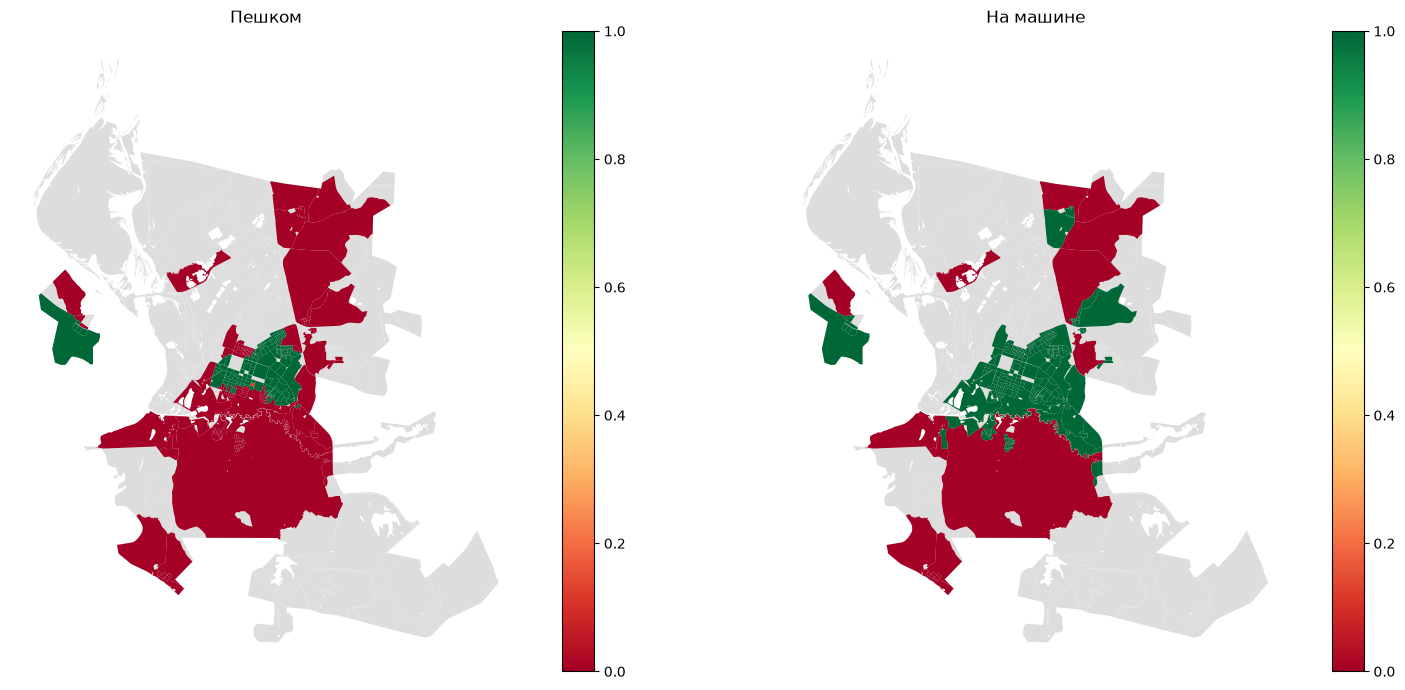

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, prov, title in zip(axes, [prov_walk, prov_drive], ['Пешком', 'На машине']):
    ax = blocks.plot(color='#ddd', ax=ax)
    blocks.join(prov).plot('provision_strong', ax=ax, cmap='RdYlGn', vmin=0, vmax=1, legend=True)
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

In [25]:
from blocksnet.analysis.indicators import calculate_density_indicators

buildings_blocks['site_area'] = buildings_blocks.area
density_df = calculate_density_indicators(buildings_blocks)
blocks.join(density_df).to_file(PROCESSED_DIR / 'density_indicators.geojson', driver='GeoJSON')
density_df[['fsi', 'gsi', 'mxi', 'l', 'osr', 'share_living', 'share_non_living']].describe()

e:\Projects\python-package-boilerplate\.venv\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: NaN of Infinity value found. Skipped. Further messages of this type will be suppressed.
  ogr_write(
e:\Projects\python-package-boilerplate\.venv\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
e:\Projects\python-package-boilerplate\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,fsi,gsi,mxi,l,osr,share_living,share_non_living
count,932.000000,932.000000,416.000000,416.000000,932.000000,416.000000,416.000000
mean,0.087328,0.043889,0.608704,1.781063,inf,1.205756,0.575307
std,0.178093,0.069710,0.377739,1.571145,NaN,1.505867,0.564151
min,0.000000,0.000000,0.000000,1.000000,0.553872,0.000000,0.100000
25%,0.000000,0.000000,0.155226,1.000000,8.171377,0.176805,0.114971
50%,0.000000,0.000000,0.839030,1.000000,NaN,0.900000,0.360608
75%,0.109124,0.088408,0.900000,2.000000,NaN,1.745131,1.000000
max,1.585954,0.643554,0.900000,16.632024,inf,14.717262,4.590319


In [26]:
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes

spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(density_df)
strelka_df = get_strelka_morphotypes(density_df)
blocks.join(spacematrix_df).to_file(PROCESSED_DIR / 'spacematrix_morphotypes.geojson', driver='GeoJSON')
blocks.join(strelka_df).to_file(PROCESSED_DIR / 'strelka_morphotypes.geojson', driver='GeoJSON')
spacematrix_clusters.to_csv(PROCESSED_DIR / 'spacematrix_clusters.csv')

print('Число кварталов по морфотипам Spacematrix:')
display(spacematrix_df['morphotype'].value_counts().to_frame('Кварталов'))
print('Характеристики групп Spacematrix (медианы по кластеру): l — этажность, fsi — плотность, mxi — доля жилья:')
display(spacematrix_clusters)
print('Число кварталов по морфотипам «Стрелки»:')
display(strelka_df['morphotype'].value_counts().to_frame('Кварталов'))

Число кварталов по морфотипам Spacematrix:


,Кварталов
morphotype,
low-rise low-density residential,216
low-rise low-density non-residential,104
mid-rise low-density residential,72
low-rise low-density mixed-use,18
mid-rise low-density non-residential,3
high-rise residential,3


Характеристики групп Spacematrix (медианы по кластеру): l — этажность, fsi — плотность, mxi — доля жилья:


,l,fsi,mxi,l_interpretation,fsi_interpretation,mxi_interpretation,morphotype
cluster,,,,,,,
0,1.000000,0.177778,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
1,1.000000,0.106269,0.900000,low-rise,low-density,residential,low-rise low-density residential
2,4.443634,0.734237,0.853955,mid-rise,low-density,residential,mid-rise low-density residential
3,14.181675,1.191228,0.892307,high-rise,None,residential,high-rise residential
4,3.122150,0.368931,0.840598,mid-rise,low-density,residential,mid-rise low-density residential
5,1.000000,0.003785,0.579294,low-rise,low-density,residential,low-rise low-density residential
6,2.000000,0.166246,0.900000,low-rise,low-density,residential,low-rise low-density residential
7,1.000000,0.012836,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
8,3.550815,0.542539,0.832933,mid-rise,low-density,residential,mid-rise low-density residential


Число кварталов по морфотипам «Стрелки»:


,Кварталов
morphotype,
low-rise model,196
low-rise non-residential,98
individual residential,96
mid-rise,22
high-rise soviet microdistrict,2
mid-rise non-residential,1
high-rise modern microdistrict,1


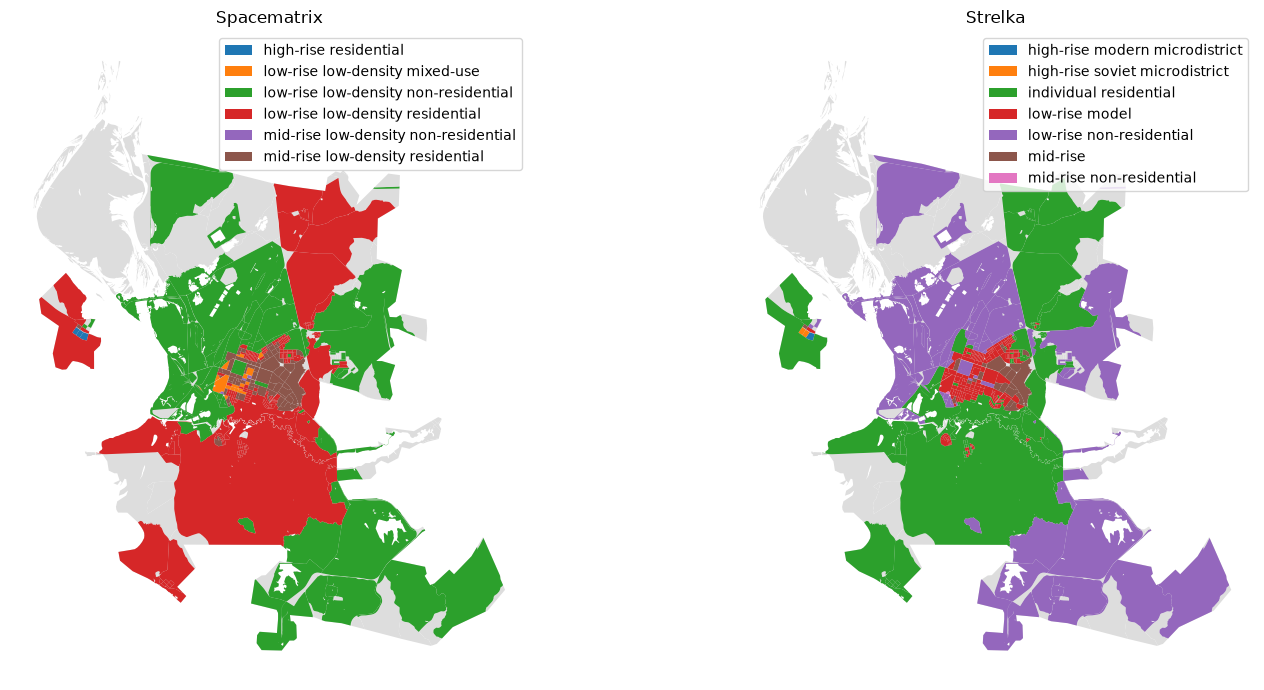

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, dfm, title in zip(axes, [spacematrix_df, strelka_df], ['Spacematrix', 'Strelka']):
    ax = blocks.plot(color='#ddd', ax=ax)
    blocks.join(dfm).plot('morphotype', legend=True, ax=ax)
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

In [28]:
from blocksnet.analysis.network.accessibility import area_accessibility

area_acc_walk = area_accessibility(acc_mx_walk, buildings_blocks)
area_acc_drive = area_accessibility(acc_mx_drive, buildings_blocks)
blocks.join(area_acc_walk).to_file(PROCESSED_DIR / 'area_accessibility_walk.geojson', driver='GeoJSON')
blocks.join(area_acc_drive).to_file(PROCESSED_DIR / 'area_accessibility_drive.geojson', driver='GeoJSON')
print('Area accessibility посчитана для обоих графов.')

Area accessibility посчитана для обоих графов.


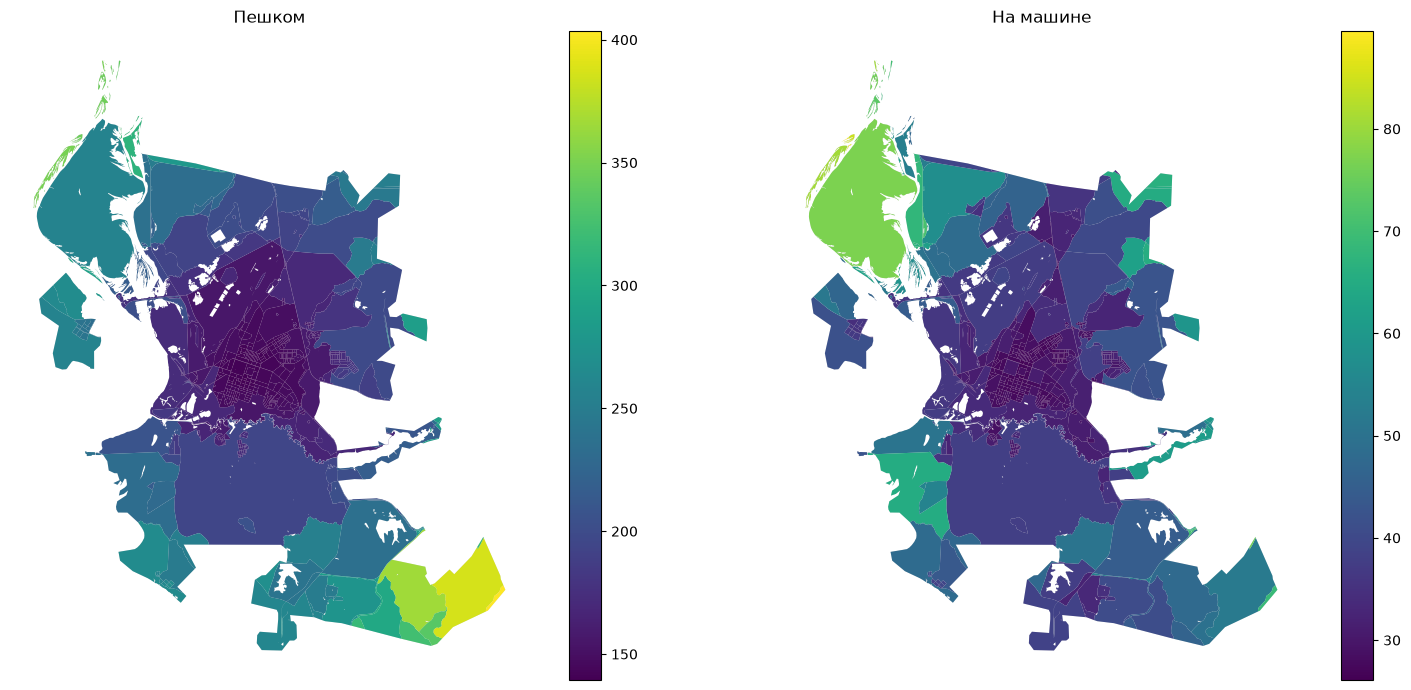

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, aa, title in zip(axes, [area_acc_walk, area_acc_drive], ['Пешком', 'На машине']):
    ax = blocks.plot(color='#ddd', ax=ax)
    blocks.join(aa).plot('area_accessibility', legend=True, ax=ax)
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## 10. Проверка результатов

Сверьте:

- число кварталов и суммы населения/мощности;
- медианное время в пути (пешком должно быть заметно больше, чем на машине);
- диапазоны плотности (FSI/GSI в разумных пределах, без NaN);
- `provision_strong` в диапазоне 0–1.

In [30]:
print('Кварталов:', len(blocks))
print('Зданий:', len(buildings), '| население (откалибровано):', int(round(buildings.population.sum())),
      '| модельная оценка до калибровки:', int(round(buildings.population_model.sum())))
print('Школ:', len(schools), '| суммарная мощность:', int(schools.capacity.sum()))
print()
print('Время в пути, мин (медиана): пешком =', round(float(np.nanmedian(acc_mx_walk.values)), 2),
      '| на машине =', round(float(np.nanmedian(acc_mx_drive.values)), 2))
print('provision_strong (медиана): пешком =', round(float(prov_walk.provision_strong.median()), 3),
      '| на машине =', round(float(prov_drive.provision_strong.median()), 3))
print()
cols = ['fsi', 'gsi', 'l', 'osr', 'share_living']
summary = pd.DataFrame({
    'Показатель': cols,
    'Минимум': [round(density_df[c].min(), 3) for c in cols],
    'Медиана': [round(density_df[c].median(), 3) for c in cols],
    'Максимум': [round(density_df[c].max(), 3) for c in cols],
})
summary

Кварталов: 932
Зданий: 10869 | население (откалибровано): 132841 | модельная оценка до калибровки: 174002
Школ: 21 | суммарная мощность: 17048

Время в пути, мин (медиана): пешком = 115.94 | на машине = 17.25
provision_strong (медиана): пешком = 1.0 | на машине = 1.0



,Показатель,Минимум,Медиана,Максимум
0,fsi,0.000,0.0,1.586
1,gsi,0.000,0.0,0.644
2,l,1.000,1.0,16.632
3,osr,0.554,inf,inf
4,share_living,0.000,0.9,14.717


## 12. Сверка с `pipeline.ipynb`

Все показатели из примера BlocksNet и то, где они находятся в этом ноутбуке и в `dashboard.html`.

| Показатель (pipeline.ipynb) | Ноутбук | Дашборд |
|---|---|---|
| Граница территории | § 1 | Карта (контур кварталов) |
| Кварталы (`cut_urban_blocks`) | § 3 | Карта, карточка «Кварталов» |
| Доли функций и преобладающая функция (`assign_land_use`) | § 4 | Слой «Функциональные зоны», график, таблица «Функциональные зоны» |
| Граф (walk и drive, OSM через iduedu) | § 5 | — (исходные данные) |
| Матрица времени между кварталами, мин | § 6 | График «Время в пути», таблица «Матрицы времени в пути», карточки «Медиана пути» |
| Здания: площади, этажность, жилая/нежилая площадь (`impute_buildings`, `aggregate_objects`) | § 7 | Таблица «Здания» |
| Население (оценка и калибровка) | § 7 | Слой «Население по кварталам», две карточки населения |
| Школы: число и вместимость (`impute_services`) | § 8 | Таблица «Школы», карточки «Школ», «Мест в школах» |
| Обеспеченность strong и weak (`competitive_provision`) | § 9 | Слои обеспеченности, график, таблицы «Сводка» и «Обеспеченность школами: итоги» |
| Нехватка и остаток мест (`demand_left`, `capacity_left`) | § 9 | Таблица «Обеспеченность школами: итоги», топ-10 худших кварталов |
| Распределение спроса между кварталами (`links`) | § 9 | Таблицы «Крупнейшие потоки к школам» (пешком и авто) |
| Плотность: FSI, GSI, L, OSR, MXI, доли жилой/нежилой площади (`calculate_density_indicators`) | § 9 | Слой FSI, график, таблица «Сводка по показателям» |
| Морфотипы Spacematrix и характеристики групп | § 9 | Слой, график, таблицы «Морфотипы» и «Группы Spacematrix» |
| Морфотипы «Стрелки» | § 9 | Слой, график, таблица «Морфотипы» |
| Доступность с учётом площади (`area_accessibility`) | § 9 | Слои (пешком, авто), график, таблица «Сводка» |

Ячейка ниже проверяет, что все файлы результатов на месте и в них есть нужные колонки.


In [31]:
required = {
    'blocks.geojson': [],
    'blocks_land_use.geojson': ['land_use', 'residential', 'business', 'industrial'],
    'accessibility_matrix_walk.csv': [],
    'accessibility_matrix_drive.csv': [],
    'buildings_blocks.geojson': ['population', 'population_model', 'footprint_area', 'build_floor_area', 'living_area'],
    'schools_blocks.geojson': ['capacity', 'count'],
    'provision_walk.geojson': ['provision_strong', 'provision_weak', 'demand_left', 'capacity_left'],
    'provision_drive.geojson': ['provision_strong', 'provision_weak', 'demand_left', 'capacity_left'],
    'provision_links_walk.csv': [],
    'provision_links_drive.csv': [],
    'provision_summary.csv': [],
    'density_indicators.geojson': ['fsi', 'gsi', 'l', 'osr', 'mxi', 'share_living', 'share_non_living'],
    'spacematrix_morphotypes.geojson': ['morphotype'],
    'spacematrix_clusters.csv': [],
    'strelka_morphotypes.geojson': ['morphotype'],
    'area_accessibility_walk.geojson': ['area_accessibility'],
    'area_accessibility_drive.geojson': ['area_accessibility'],
}
rows = []
for name, cols in required.items():
    path = PROCESSED_DIR / name
    if not path.exists():
        rows.append([name, 'НЕТ ФАЙЛА', ''])
        continue
    if name.endswith('.geojson'):
        columns = gpd.read_file(path, rows=1).columns
    else:
        columns = pd.read_csv(path, nrows=1).columns
    missing = [col for col in cols if col not in columns]
    rows.append([name, 'ок' if not missing else 'не хватает колонок', ', '.join(missing)])
check_df = pd.DataFrame(rows, columns=['Файл', 'Статус', 'Пропущено'])
display(check_df)
print('Всё на месте' if (check_df['Статус'] == 'ок').all() else 'Есть пропуски — см. таблицу')


,Файл,Статус,Пропущено
0,blocks.geojson,ок,
1,blocks_land_use.geojson,ок,
2,accessibility_matrix_walk.csv,ок,
3,accessibility_matrix_drive.csv,ок,
4,buildings_blocks.geojson,ок,
5,schools_blocks.geojson,ок,
6,provision_walk.geojson,ок,
7,provision_drive.geojson,ок,
8,provision_links_walk.csv,ок,
9,provision_links_drive.csv,ок,


Всё на месте


## 11. Инструкции повторного запуска

- **Полный перезапуск:** Kernel → Restart & Run All. Ячейки выполнятся заново.
- **Переиспользование данных:** готовые GeoJSON и графы в `data/berezniki/` подхватятся автоматически, скачивание не повторится.
- **Принудительное скачивание заново:** удалите нужный файл в `data/berezniki/raw/` (например, `raw/roads.geojson`) и запустите ячейку загрузки.
- **Принудительная перезагрузка графов:** удалите `processed/graph_walk.graphml` и/или `processed/graph_drive.graphml`.
- **Сброс результатов:** удалите нужные файлы в `data/berezniki/processed/` и перезапустите соответствующий блок.
- Матрицы времени хранятся в `processed/accessibility_matrix_*.csv`, итоги — в `processed/*.geojson`.